# 02 — Sampling From Any Distribution

Notebook 01 left us with a stream of uniform numbers in $[0, 1)$. That is all a random
number generator ever gives you. Yet `np.random.normal()` returns normally distributed
values, `np.random.gamma()` returns gamma ones, and nobody stops to ask how.

**The question this notebook answers:** given uniform numbers, how do you get a draw from
*any* distribution you like?

Two general methods, both built from scratch, both about ten lines of code. After this
notebook the library call stops being magic.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
from scipy import stats

from src.config import load_settings, make_rng
from src.draw.discrete import AliasTable, cumulative_search_sample
from src.draw.inverse_transform import (
    exponential_inv_cdf,
    numeric_inverse_cdf,
    sample_via_inverse_cdf,
)
from src.draw.rejection import rejection_sample
from src.reporting import save_results
from src.visualisation import (
    plot_inverse_cdf_mechanism,
    plot_rejection_illustration,
    plot_samples_vs_density,
    save_figure,
)

settings = load_settings()
rng = make_rng()
N = settings.draw.n_samples
RATE = settings.draw.exponential_rate

print(f"seed = {settings.seed}, n = {N:,}, exponential rate = {RATE}")

seed = 20260909, n = 50,000, exponential rate = 1.5


## Method 1: inverse transform sampling

The idea in one line. If $U$ is uniform on $[0,1)$ and $F$ is a cumulative distribution
function, then

$$X = F^{-1}(U)$$

has distribution $F$. That is the whole method.

Why it works: $P(X \le x) = P(F^{-1}(U) \le x) = P(U \le F(x)) = F(x)$, because $U$ is
uniform. The CDF maps the distribution onto $[0,1]$; the inverse CDF maps uniforms back.

Picture it as drawing a height on the vertical axis and reading the value off the
horizontal one. Where the CDF is steep — where the density is high — a wide band of
uniforms maps to a narrow band of $x$, so that region gets more draws.

/workspaces/sampling_101/outputs/figures/02_inverse_cdf_mechanism.png


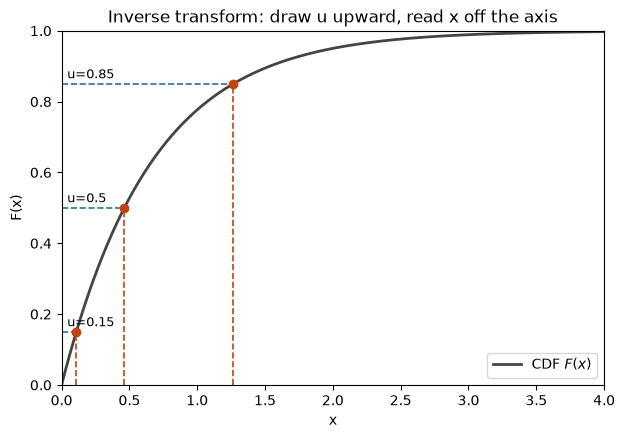

In [2]:
fig = plot_inverse_cdf_mechanism(
    cdf=lambda x: 1.0 - np.exp(-RATE * x),
    inv_cdf=exponential_inv_cdf(RATE),
    lo=0.0,
    hi=4.0,
)
print(save_figure(fig, "02_inverse_cdf_mechanism"))

### The closed-form case

For the exponential distribution, $F(x) = 1 - e^{-\lambda x}$ inverts by hand:

$$F^{-1}(u) = -\frac{\log(1-u)}{\lambda}$$

One logarithm per draw, no rejected work, exact.

sample mean     0.66376   (theory 0.66667)
sample variance 0.43903   (theory 0.44444)

KS test against the exact exponential: D = 0.00326, p = 0.662


/workspaces/sampling_101/outputs/figures/02_inverse_transform_exponential.png


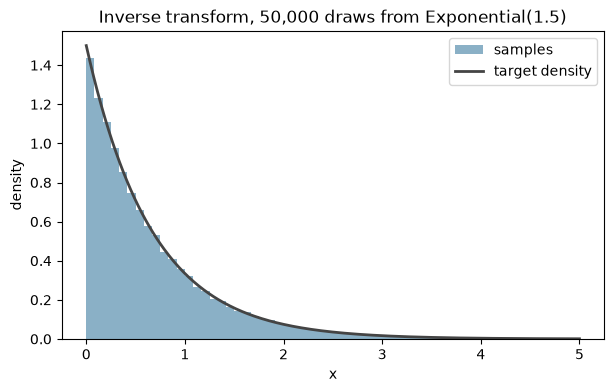

In [3]:
exponential = sample_via_inverse_cdf(exponential_inv_cdf(RATE), N, rng)

ks_exponential = stats.kstest(exponential, stats.expon(scale=1 / RATE).cdf)
print(f"sample mean     {exponential.mean():.5f}   (theory {1 / RATE:.5f})")
print(f"sample variance {exponential.var():.5f}   (theory {1 / RATE**2:.5f})")
print(f"\nKS test against the exact exponential: D = {ks_exponential.statistic:.5f}, "
      f"p = {ks_exponential.pvalue:.3f}")

fig = plot_samples_vs_density(
    exponential,
    lambda x: RATE * np.exp(-RATE * x),
    0.0,
    5.0,
    f"Inverse transform, {N:,} draws from Exponential({RATE})",
)
print(save_figure(fig, "02_inverse_transform_exponential"))

### The general case: when you cannot invert by hand

Most distributions have no tidy closed-form inverse CDF — the normal is the obvious
example. But the method still applies, because the inverse can be built numerically:
integrate the density on a grid, normalise, then interpolate.

This is what makes inverse transform a *general* method rather than a trick for a handful
of textbook distributions. Note that we only need the density up to a constant; the
normalisation falls out of the integration.

In [4]:
def normal_pdf(x: np.ndarray) -> np.ndarray:
    """Unnormalised standard normal. The missing 1/sqrt(2*pi) does not matter."""
    return np.exp(-0.5 * x**2)


normal_inv_cdf = numeric_inverse_cdf(normal_pdf, lo=-6.0, hi=6.0, grid=settings.draw.grid_points)
normal_samples = sample_via_inverse_cdf(normal_inv_cdf, N, rng)

ks_normal = stats.kstest(normal_samples, stats.norm.cdf)
print(f"KS test against the exact normal: D = {ks_normal.statistic:.5f}, "
      f"p = {ks_normal.pvalue:.3f}")
print(f"sample mean {normal_samples.mean():+.5f}, sd {normal_samples.std():.5f}")

KS test against the exact normal: D = 0.00307, p = 0.732
sample mean -0.00012, sd 0.99952


A goodness-of-fit test cannot distinguish our from-scratch draws from the real thing.

It works just as well on a shape with no name at all — here a bimodal mixture, supplied
only as a density:

/workspaces/sampling_101/outputs/figures/02_inverse_transform_bimodal.png
draws below x = 1: 50.60%   exact: 50.59%


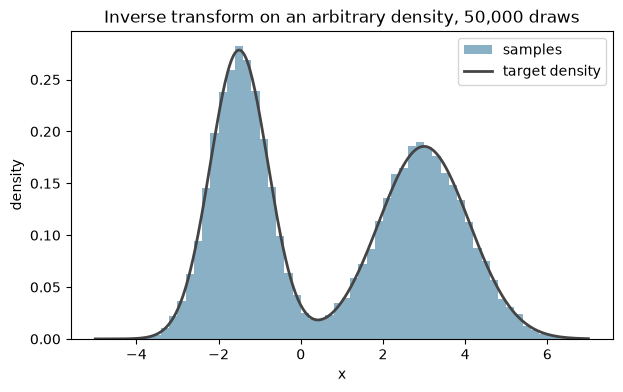

In [5]:
def bimodal_pdf(x: np.ndarray) -> np.ndarray:
    left = np.exp(-0.5 * ((x + 1.5) / 0.7) ** 2)
    right = np.exp(-0.5 * ((x - 3.0) / 1.1) ** 2)
    return 0.6 * left + 0.4 * right


bimodal_inv_cdf = numeric_inverse_cdf(bimodal_pdf, -5.0, 7.0, grid=settings.draw.grid_points)
bimodal = sample_via_inverse_cdf(bimodal_inv_cdf, N, rng)

grid = np.linspace(-5.0, 7.0, 4000)
normaliser = float(np.trapezoid(bimodal_pdf(grid), grid))
fig = plot_samples_vs_density(
    bimodal,
    lambda x: bimodal_pdf(x) / normaliser,
    -5.0,
    7.0,
    f"Inverse transform on an arbitrary density, {N:,} draws",
)
print(save_figure(fig, "02_inverse_transform_bimodal"))

# Note the 0.6 and 0.4 above are NOT the mixture weights: they scale unnormalised bumps of
# different widths (0.7 and 1.1), so the actual mass split is 0.6*0.7 to 0.4*1.1. Compare
# the draws against the exact share obtained by integrating the density, not against 60%.
left = grid < 1.0
exact_left_share = float(np.trapezoid(bimodal_pdf(grid[left]), grid[left]) / normaliser)
observed_left_share = float((bimodal < 1.0).mean())
print(f"draws below x = 1: {observed_left_share:.2%}   exact: {exact_left_share:.2%}")

## Method 2: rejection sampling

Inverse transform needs a CDF you can integrate, even numerically. Rejection sampling
needs only the ability to *evaluate* the density.

Cover the target density $p$ with an envelope $m \cdot q(x)$ that you can sample from.
Draw a candidate from $q$, draw a height uniformly under the envelope, and keep the
candidate if the height falls under $p$. The survivors are distributed exactly as $p$.

The price is the rejected work: the acceptance rate is exactly $1/m$.

In [6]:
LO, HI = -4.0, 4.0
M = (HI - LO) / np.sqrt(2 * np.pi)  # envelope: uniform on [-4, 4], scaled to cover the peak

result = rejection_sample(
    target_pdf=lambda x: np.exp(-0.5 * x**2) / np.sqrt(2 * np.pi),
    proposal_sampler=lambda n, r: r.uniform(LO, HI, size=n),
    proposal_pdf=lambda x: np.full_like(x, 1.0 / (HI - LO)),
    m=M,
    n=N,
    rng=rng,
    check_grid=np.linspace(LO, HI, 1000),
)

print(f"envelope constant m = {M:.4f}")
print(f"theoretical acceptance rate 1/m = {1 / M:.4%}")
print(f"empirical acceptance rate       = {result.acceptance_rate:.4%}")
print(f"\nproposals drawn: {result.n_proposed:,} to keep {N:,} samples")

ks_rejection = stats.kstest(result.samples, stats.norm.cdf)
print(f"KS test against the exact normal: D = {ks_rejection.statistic:.5f}, "
      f"p = {ks_rejection.pvalue:.3f}")

envelope constant m = 3.1915
theoretical acceptance rate 1/m = 31.3329%
empirical acceptance rate       = 31.1672%

proposals drawn: 175,534 to keep 50,000 samples
KS test against the exact normal: D = 0.00334, p = 0.630


The acceptance rate lands on $1/m$, as the theory says it must. Here is what is actually
happening — every rejected point is wasted work, and the gap between the envelope and the
density is exactly that waste:

/workspaces/sampling_101/outputs/figures/02_rejection_sampling.png


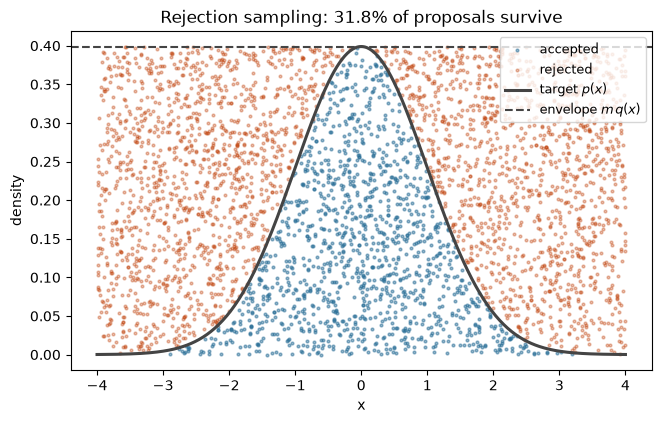

In [7]:
fig = plot_rejection_illustration(
    target_pdf=lambda x: np.exp(-0.5 * x**2) / np.sqrt(2 * np.pi),
    lo=LO,
    hi=HI,
    m=M,
    n=4000,
    rng=rng,
)
print(save_figure(fig, "02_rejection_sampling"))

A tighter envelope means less waste. A uniform envelope over a bell-shaped target is a
poor fit — two thirds of the work is thrown away — but it is trivial to set up, and for a
one-off it is often the right trade.

## The discrete case: sampling categories

Choosing among $k$ outcomes with given probabilities is the most common draw in applied
work: bootstrap indices, categorical features, weighted sampling. The obvious method
binary-searches a cumulative sum, at $O(\log k)$ per draw. The alias method does $O(k)$
setup once, then answers every draw in constant time with one uniform and one integer.

In [8]:
probs = np.array([0.5, 0.25, 0.15, 0.08, 0.02])
n_draws = 200_000

alias_draws = AliasTable(probs).sample(n_draws, rng)
search_draws = cumulative_search_sample(probs, n_draws, rng)

alias_freq = np.bincount(alias_draws, minlength=probs.size) / n_draws
search_freq = np.bincount(search_draws, minlength=probs.size) / n_draws

print("category   target    alias    cumulative-search")
for k, (target, a, s) in enumerate(zip(probs, alias_freq, search_freq, strict=True)):
    print(f"    {k}      {target:.3f}    {a:.4f}         {s:.4f}")

category   target    alias    cumulative-search
    0      0.500    0.5001         0.4987
    1      0.250    0.2493         0.2514
    2      0.150    0.1513         0.1495
    3      0.080    0.0795         0.0801
    4      0.020    0.0199         0.0202


Both reproduce the requested probabilities, including the rare 2% category. The alias
table is the one to reach for when you draw many times from a fixed distribution.

## Saving the results

In [9]:
results = {
    "notebook": "02_sampling_from_any_distribution",
    "seed": settings.seed,
    "n_samples": N,
    "inverse_transform": {
        "exponential": {
            "rate": RATE,
            "sample_mean": float(exponential.mean()),
            "theoretical_mean": 1 / RATE,
            "ks_statistic": float(ks_exponential.statistic),
            "ks_p_value": float(ks_exponential.pvalue),
        },
        "normal_numeric_grid": {
            "grid_points": settings.draw.grid_points,
            "sample_mean": float(normal_samples.mean()),
            "sample_sd": float(normal_samples.std()),
            "ks_statistic": float(ks_normal.statistic),
            "ks_p_value": float(ks_normal.pvalue),
        },
        "bimodal": {
            "observed_share_below_1": observed_left_share,
            "exact_share_below_1": exact_left_share,
            "note": (
                "0.6/0.4 scale unnormalised bumps of different widths, so they are not the "
                "mixture weights; the exact share comes from integrating the density."
            ),
        },
    },
    "rejection": {
        "envelope_constant_m": float(M),
        "theoretical_acceptance_rate": float(1 / M),
        "empirical_acceptance_rate": float(result.acceptance_rate),
        "n_proposed": int(result.n_proposed),
        "n_kept": int(N),
        "ks_statistic": float(ks_rejection.statistic),
        "ks_p_value": float(ks_rejection.pvalue),
    },
    "discrete": {
        "target_probabilities": probs.tolist(),
        "alias_frequencies": alias_freq.tolist(),
        "cumulative_search_frequencies": search_freq.tolist(),
        "n_draws": n_draws,
    },
    "findings": [
        "Inverse transform turns uniforms into any distribution via F^-1, exactly.",
        "The inverse can be built numerically from the density alone, so the method is general.",
        "An unnormalised density is enough: the normalising constant falls out of the integration.",
        f"Rejection sampling accepted {result.acceptance_rate:.1%} of proposals, "
        f"matching the theoretical 1/m = {1 / M:.1%}.",
        "Every sampler here passes a KS test against its exact target distribution.",
    ],
    "figures": [
        "02_inverse_cdf_mechanism",
        "02_inverse_transform_exponential",
        "02_inverse_transform_bimodal",
        "02_rejection_sampling",
    ],
}
print(save_results("02_sampling_from_any_distribution", results))

/workspaces/sampling_101/outputs/results/02_sampling_from_any_distribution.json


## What this bought you

- **Inverse transform** ($X = F^{-1}(U)$) is exact and wastes nothing, when you can
  invert the CDF — analytically or numerically on a grid.
- **Rejection sampling** needs only to evaluate the density, and costs $1/m$ in accepted
  draws. Use it when the CDF is out of reach.
- **Alias tables** make repeated categorical draws constant-time.
- An unnormalised density is enough for both methods. That matters enormously in Bayesian
  work, where the normalising constant is exactly the thing you cannot compute.

Both methods are ten lines. The library was never doing anything you could not do.

Next: [03 — When Your Sample Is Biased](03_when_your_sample_is_biased.ipynb), where the
sampling is correct and the *answer* is still wrong.